# v3 · 01 Calibration report (design note §5.1)

Do the probability treatments C1–C3 fix v2's inflated P(Sell)? This notebook answers only that. It computes **out-of-sample class probabilities** on the 2013–2022 development walk-forward (yearly refits, v2's frozen HGB hyper-parameters, open→open label, gap 6) and compares them with what actually happened.

**No trading rule, expected return or backtest is computed here.** Per [docs/v3_design_note.md](../docs/v3_design_note.md) §5.1, this report is committed before any v3 trading result exists.

| ID | Probabilities |
|---|---|
| C0 | balanced class weights, raw (v2 as is; reference) |
| C1 | no class weights |
| C2 | balanced weights + prior correction p_k ∝ p̃_k·π_k |
| C3 | balanced weights + sigmoid calibration on `TimeSeriesSplit(5, gap=6)` |

**Pass rule (fixed in advance):** |mean P(Sell) − actual Sell share| ≤ 3 percentage points in at least 8 of the 10 years.

In [1]:
import sys, json, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, v3
from src.data import load_snapshot
from src.dataset import build_dataset_v2

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.4f}".format)
OUT = config.OUTPUT_DIR / "v3"; FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
def savefig(name): plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight")

raw = load_snapshot()
ds = build_dataset_v2(raw)
params = v3.v2_params()
DEV = list(range(2013, 2023))
print("v2 frozen HGB params:", params)

v2 frozen HGB params: {'clf__l2_regularization': 0.17336465350777208, 'clf__learning_rate': 0.032268708256236636, 'clf__max_depth': 3, 'clf__max_iter': 51, 'clf__min_samples_leaf': 153}


## 1. Out-of-sample probabilities, 2013–2022 (yearly refits)

In [2]:
PROBA = {k: v3.walk_forward_proba(ds, k, DEV, params) for k in v3.CANDIDATES}
YEARLY = {k: v3.yearly_calibration(PROBA[k], ds["label"]) for k in v3.CANDIDATES}
summary = pd.DataFrame({
    k: {"log_loss (mean of years)": y["log_loss"].mean(), "brier (mean of years)": y["brier"].mean(),
        "mean P(Sell)": y["pred_Sell"].mean(), "actual Sell share": y["actual_Sell"].mean(),
        "mean |Sell gap| pp": y["sell_gap_pp"].abs().mean(),
        "years within ±3 pp": int((y["sell_gap_pp"].abs() <= 3).sum()),
        "passes §5.1": v3.calibration_passes(y)}
    for k, y in YEARLY.items()}).T
print("uniform-guess log loss = ln 3 =", round(np.log(3), 4))
summary

uniform-guess log loss = ln 3 = 1.0986


,log_loss (mean of years),brier (mean of years),mean P(Sell),actual Sell share,mean |Sell gap| pp,years within ±3 pp,passes §5.1
C0,1.0387,0.6233,0.3033,0.2073,10.3559,1,False
C1,1.0157,0.6064,0.2182,0.2073,6.4729,4,False
C2,1.0175,0.6080,0.2151,0.2073,6.2742,4,False
C3,1.0278,0.6176,0.2441,0.2073,8.4604,3,False


## 2. Sell gap by year (mean predicted P(Sell) − actual Sell share, percentage points)

,C0,C1,C2,C3
year,,,,
2013,13.6000,9.3000,8.6000,15.1000
2014,7.1000,0.9000,0.8000,8.2000
2015,6.0000,-2.4000,-2.3000,-0.2000
2016,12.7000,5.2000,4.8000,9.2000
2017,19.8000,12.2000,11.7000,17.0000
2018,-0.5000,-9.9000,-10.2000,-6.3000
2019,14.0000,5.3000,5.1000,9.2000
2020,13.6000,2.0000,2.1000,-0.7000
2021,12.9000,2.8000,2.2000,2.0000


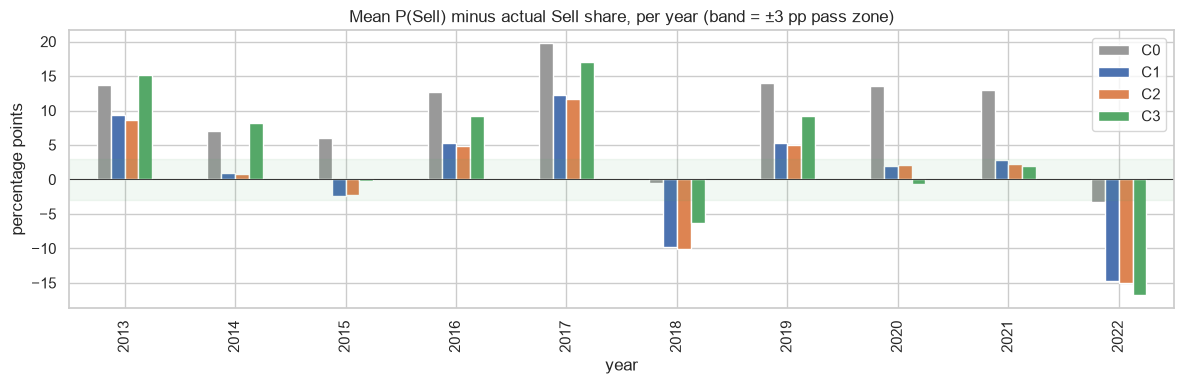

In [3]:
gaps = pd.DataFrame({k: y["sell_gap_pp"] for k, y in YEARLY.items()})
display(gaps.round(1))
ax = gaps.plot(kind="bar", figsize=(12, 4), color=["0.6", "C0", "C1", "C2"])
ax.axhspan(-3, 3, color="C2", alpha=0.08); ax.axhline(0, color="k", lw=0.6)
ax.set_ylabel("percentage points"); ax.set_title("Mean P(Sell) minus actual Sell share, per year (band = ±3 pp pass zone)")
plt.tight_layout(); savefig("sell_gap_by_year"); plt.show()

## 3. Predicted vs actual share of every class (mean over the 10 years)

In [4]:
shares = pd.DataFrame({k: {f"{s} {config.CLASS_NAMES[c]}": y[f"{s}_{config.CLASS_NAMES[c]}"].mean()
                           for c in config.CLASSES for s in ("pred", "actual")} for k, y in YEARLY.items()}).T
shares

,pred Sell,actual Sell,pred Hold,actual Hold,pred Buy,actual Buy
C0,0.3033,0.2073,0.3755,0.4540,0.3212,0.3387
C1,0.2182,0.2073,0.4508,0.4540,0.3310,0.3387
C2,0.2151,0.2073,0.4540,0.4540,0.3309,0.3387
C3,0.2441,0.2073,0.3988,0.4540,0.3571,0.3387


## 4. Reliability (pooled 2013–2022): when the model says x%, how often does it happen?

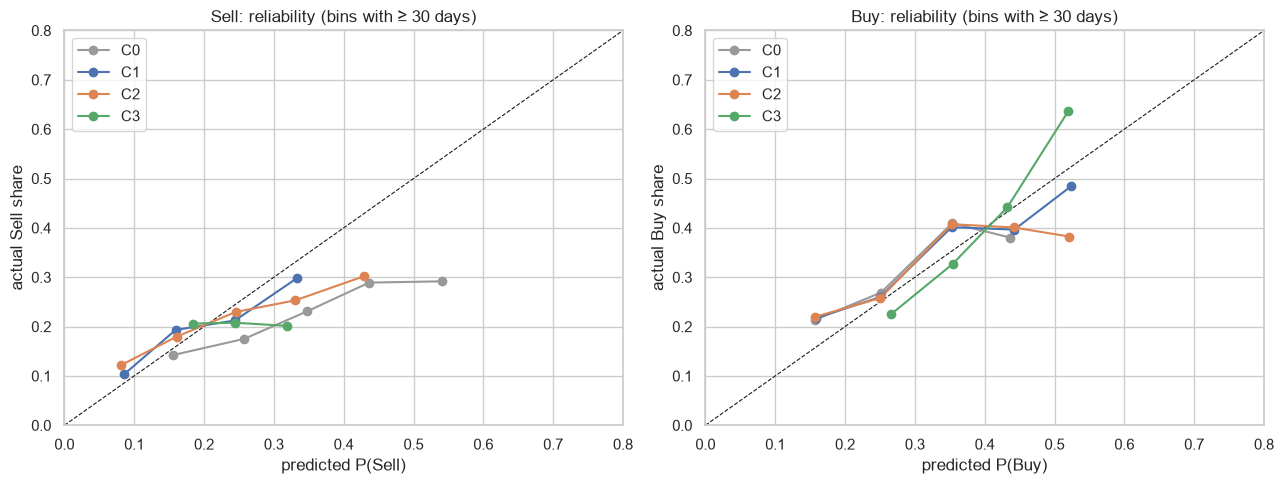

C0 Sell bins:


,n,mean_pred,actual
bin,,,
"(0.1, 0.2]",359,0.1550,0.1420
"(0.2, 0.3]",851,0.2570,0.1750
"(0.3, 0.4]",952,0.3480,0.2310
"(0.4, 0.5]",294,0.4360,0.2890
"(0.5, 0.6]",48,0.5410,0.2920


C1 Sell bins:


,n,mean_pred,actual
bin,,,
"(-0.001, 0.1]",165,0.0850,0.1030
"(0.1, 0.2]",818,0.1590,0.1930
"(0.2, 0.3]",1233,0.2440,0.2120
"(0.3, 0.4]",272,0.3330,0.2980


C2 Sell bins:


,n,mean_pred,actual
bin,,,
"(-0.001, 0.1]",180,0.0810,0.1220
"(0.1, 0.2]",902,0.1610,0.1800
"(0.2, 0.3]",1149,0.2460,0.2300
"(0.3, 0.4]",241,0.3310,0.2530
"(0.4, 0.5]",43,0.4300,0.3020


C3 Sell bins:


,n,mean_pred,actual
bin,,,
"(0.1, 0.2]",194,0.1840,0.2060
"(0.2, 0.3]",2190,0.2450,0.2080
"(0.3, 0.4]",134,0.3180,0.2010


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
REL = {}
for j, (cls, name) in enumerate([(-1, "Sell"), (1, "Buy")]):
    ax[j].plot([0, 1], [0, 1], color="k", lw=0.8, ls="--")
    for i, k in enumerate(v3.CANDIDATES):
        t = v3.reliability(PROBA[k], ds["label"], cls)
        t = t[t["n"] >= 30]                       # hide bins with too few days to read
        REL[(k, name)] = t
        ax[j].plot(t["mean_pred"], t["actual"], marker="o", label=k, color=["0.6", "C0", "C1", "C2"][i])
    ax[j].set_xlim(0, 0.8); ax[j].set_ylim(0, 0.8)
    ax[j].set_xlabel(f"predicted P({name})"); ax[j].set_ylabel(f"actual {name} share"); ax[j].set_title(f"{name}: reliability (bins with ≥ 30 days)")
    ax[j].legend()
plt.tight_layout(); savefig("reliability"); plt.show()
for (k, name), t in REL.items():
    if name == "Sell": print(k, "Sell bins:"); display(t.round(3))

## 5. Save

In [6]:
res = {"design_note_sha256": (config.ROOT / "docs" / "v3_design_note.sha256").read_text().split()[0],
       "dev_years": DEV, "params": params,
       "summary": json.loads(summary.to_json(orient="index")),
       "yearly": {k: json.loads(y.round(5).to_json(orient="index")) for k, y in YEARLY.items()}}
(OUT / "calibration.json").write_text(json.dumps(res, indent=2))
pd.concat({k: p[config.CLASSES] for k, p in PROBA.items()}, axis=1).round(6).to_csv(OUT / "dev_probabilities.csv")
print("saved outputs/v3/calibration.json, dev_probabilities.csv, figures/")

saved outputs/v3/calibration.json, dev_probabilities.csv, figures/
